# 04c Drift and Network Diagnostics

Notebook 04b measured *how much* each dataset changes over time. This notebook asks what that
means for modelling, using four diagnostics:

| Section | Question | Method | Informs |
|---|---|---|---|
| 1 | Can a model tell an early period from a late one, and which features give it away? | Adversarial validation (Lecture 7 idea: a classifier trained to separate two groups) | Feature engineering: which features act as time stamps |
| 2 | Which features simply count time? | Correlation with time, and the `day - D` re-anchoring | Feature engineering for IEEE-CIS D columns |
| 3 | How fast does a model trained on the past get worse? | Train once on early weeks, score every later week; compare with weekly PSI | M2 (sliding-window retraining) and the TA's drift-vs-performance check |
| 4 | Do frauds cluster on shared entities, and how much of that is still visible under a 7-day label delay? | Homophily and "guilt by association" on cards, merchants, addresses and email domains (Lecture 8) | Card-history features, M3, and the TA's label-leakage concern |

All analysis uses the training files only. Figures are saved to `reports/figures/04c_*`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA_DIR = Path("../data/raw")
INTERIM_DIR = Path("../data/interim")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
LABEL_DELAY_DAYS = 7
SEED = 4012

## 0. Load data (same time axis as notebook 04b)

In [2]:
sparkov = pd.read_csv(DATA_DIR / "fraudTrain.csv")
ts = pd.to_datetime(sparkov["trans_date_trans_time"])
sparkov["day"] = (ts - ts.min()).dt.days
sparkov["week"] = sparkov["day"] // 7
sparkov["hour"] = ts.dt.hour
sparkov["age"] = (ts - pd.to_datetime(sparkov["dob"])).dt.days / 365.25
lat1, lon1, lat2, lon2 = (np.radians(sparkov[c]) for c in ["lat", "long", "merch_lat", "merch_long"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
sparkov["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
sparkov["category_code"] = sparkov["category"].astype("category").cat.codes
sparkov["label"] = sparkov["is_fraud"]

ieee_num = (["TransactionAmt", "card1", "card2", "card3", "card5", "addr1", "dist1"]
            + [f"C{i}" for i in range(1, 15)] + [f"D{i}" for i in range(1, 16)])
ieee = pd.read_csv(DATA_DIR / "train_transaction.csv",
                   usecols=["TransactionID", "isFraud", "TransactionDT", "ProductCD", "P_emaildomain"] + ieee_num)
ieee["day"] = ((ieee["TransactionDT"] - ieee["TransactionDT"].min()) // 86400).astype(int)
ieee["week"] = ieee["day"] // 7
ieee["label"] = ieee["isFraud"]
if (INTERIM_DIR / "ieee_card_id.csv").exists():
    ieee = ieee.merge(pd.read_csv(INTERIM_DIR / "ieee_card_id.csv"), on="TransactionID", how="left")

SPARKOV_FEATURES = ["amt", "hour", "age", "distance_km", "city_pop", "category_code", "lat", "long"]
IEEE_FEATURES = ieee_num
print(f"Sparkov {len(sparkov):,} rows | IEEE-CIS {len(ieee):,} rows")

Sparkov 1,296,675 rows | IEEE-CIS 590,540 rows


## 1. Adversarial validation: early period versus late period

A classifier is trained to tell the first 50% of the timeline from the last 20%, using the
model features only (no labels). If it cannot (AUC near 0.5), the two periods look alike. If
it can (AUC near 1), the features carry a time stamp, and a fraud model can learn rules that
only hold in the training period. The single-feature AUC (distance from 0.5) shows which
features give the period away.

Sparkov: early-vs-late classifier AUC = 0.986
IEEE-CIS: early-vs-late classifier AUC = 0.911


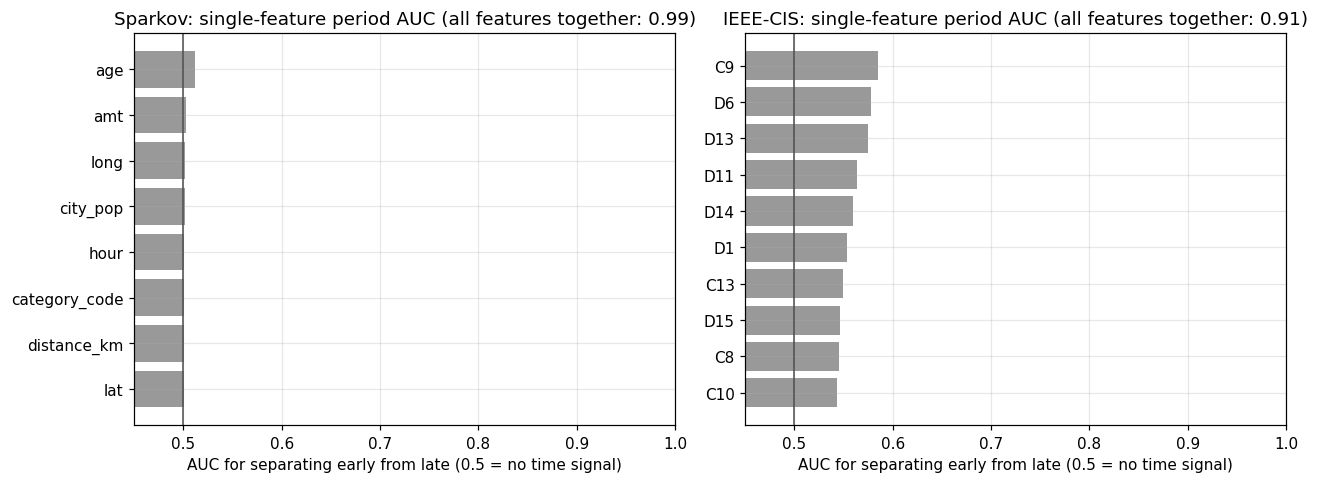

In [3]:
def adversarial(df, features, sample=200_000):
    early = df[df["day"] <= df["day"].quantile(0.5)]
    late = df[df["day"] >= df["day"].quantile(0.8)]
    data = pd.concat([early.assign(period=0), late.assign(period=1)])
    data = data.sample(min(sample, len(data)), random_state=SEED)
    X, y = data[features], data["period"].to_numpy()
    rng = np.random.default_rng(SEED)
    test = rng.random(len(data)) < 0.3
    model = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(X[~test], y[~test])
    overall = roc_auc_score(y[test], model.predict_proba(X[test])[:, 1])
    single = {}
    for f in features:
        x = data[f]
        ok = x.notna().to_numpy()
        single[f] = abs(roc_auc_score(y[ok], x[ok]) - 0.5) + 0.5 if ok.sum() > 100 and len(np.unique(y[ok])) == 2 else np.nan
    return overall, pd.Series(single).sort_values(ascending=False)


adv = {}
for name, df, feats in [("Sparkov", sparkov, SPARKOV_FEATURES), ("IEEE-CIS", ieee, IEEE_FEATURES)]:
    overall, single = adversarial(df, feats)
    adv[name] = (overall, single)
    print(f"{name}: early-vs-late classifier AUC = {overall:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, (overall, single)) in zip(axes, adv.items()):
    top = single.head(10)[::-1]
    ax.barh(top.index, top.values, color=["tab:red" if v > 0.7 else "0.6" for v in top.values])
    ax.axvline(0.5, color="0.3", lw=1)
    ax.set_xlim(0.45, 1.0)
    ax.set_title(f"{name}: single-feature period AUC (all features together: {overall:.2f})")
    ax.set_xlabel("AUC for separating early from late (0.5 = no time signal)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04c_adversarial_validation.png", bbox_inches="tight")
plt.show()

### 1b. Where does Sparkov's time signal come from?

Every single Sparkov feature has a period AUC of about 0.5, yet together they separate the
periods almost perfectly. The check below removes features one group at a time.

In [4]:
def adversarial_auc(df, features, sample=200_000):
    early = df[df["day"] <= df["day"].quantile(0.5)]
    late = df[df["day"] >= df["day"].quantile(0.8)]
    data = pd.concat([early.assign(period=0), late.assign(period=1)]).sample(sample, random_state=SEED)
    test = np.random.default_rng(SEED).random(len(data)) < 0.3
    y = data["period"].to_numpy()
    m = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(data.loc[~test, features], y[~test])
    return roc_auc_score(y[test], m.predict_proba(data.loc[test, features])[:, 1])


checks = {
    "all features": SPARKOV_FEATURES,
    "without age": [f for f in SPARKOV_FEATURES if f != "age"],
    "without location (lat, long, city_pop)": [f for f in SPARKOV_FEATURES if f not in ("lat", "long", "city_pop")],
    "age + city_pop only": ["age", "city_pop"],
}
pd.Series({k: round(adversarial_auc(sparkov, v), 3) for k, v in checks.items()}).to_frame("early-vs-late AUC")

,early-vs-late AUC
all features,0.986
without age,0.503
"without location (lat, long, city_pop)",0.646
age + city_pop only,0.960


## 2. Features that count time: the IEEE-CIS D columns

Many D columns are "days since an earlier event" (for example since the card's first
transaction). For an old card they keep growing, so their raw value partly measures *when*
the transaction happened. Subtracting the column from the transaction day re-anchors it to a
fixed date (`day - D`), the same idea Lycia used to build the card ID from D1. If the
re-anchored version is much less correlated with time, it is the safer feature.

,missing (%),corr with day (raw),corr with day (day - D)
feature,,,
D1,0.2,0.098,0.497
D2,47.5,0.015,0.360
D3,44.5,-0.008,0.850
D4,28.6,0.053,0.390
D5,52.5,0.009,0.773
D6,87.6,0.115,0.572
D7,93.4,-0.037,0.793
D8,87.3,-0.072,0.506
D9,87.3,-0.030,1.000


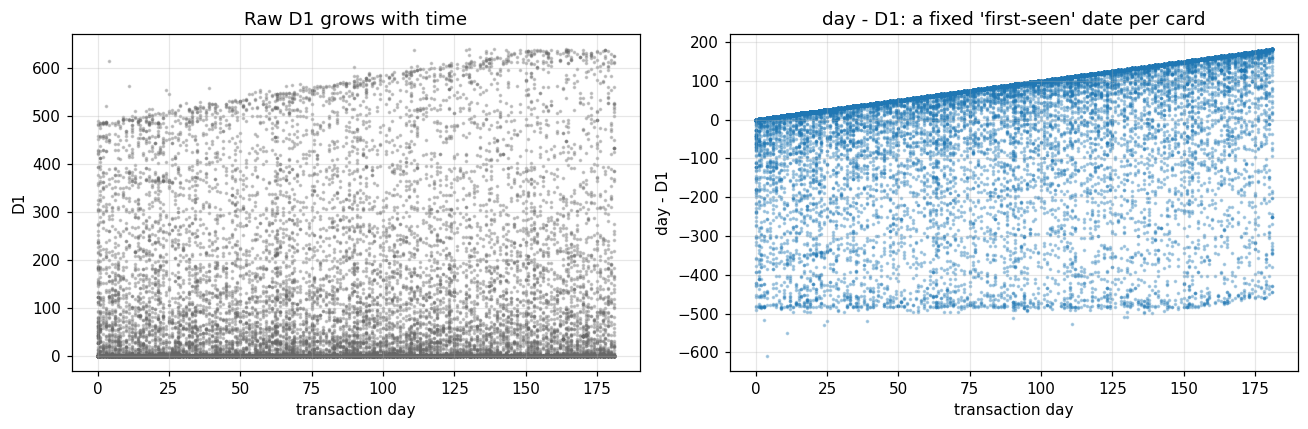

In [5]:
rows = []
for c in [f"D{i}" for i in range(1, 16)]:
    ok = ieee[c].notna()
    if ok.sum() < 1000:
        continue
    raw_corr = ieee.loc[ok, [c, "day"]].corr(method="spearman").iloc[0, 1]
    anchored = ieee.loc[ok, "day"] - ieee.loc[ok, c]
    anch_corr = pd.concat([anchored, ieee.loc[ok, "day"]], axis=1).corr(method="spearman").iloc[0, 1]
    rows.append({"feature": c, "missing (%)": round(100 * (1 - ok.mean()), 1),
                 "corr with day (raw)": round(raw_corr, 3), "corr with day (day - D)": round(anch_corr, 3)})
time_corr = pd.DataFrame(rows).set_index("feature")
display(time_corr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = ieee[ieee["D1"].notna()].sample(20_000, random_state=SEED)
axes[0].scatter(s["day"], s["D1"], s=2, alpha=0.3, color="0.4")
axes[0].set_title("Raw D1 grows with time")
axes[0].set_xlabel("transaction day"); axes[0].set_ylabel("D1")
axes[1].scatter(s["day"], s["day"] - s["D1"], s=2, alpha=0.3, color="tab:blue")
axes[1].set_title("day - D1: a fixed 'first-seen' date per card")
axes[1].set_xlabel("transaction day"); axes[1].set_ylabel("day - D1")
fig.tight_layout()
fig.savefig(FIG_DIR / "04c_d1_time_anchor.png", bbox_inches="tight")
plt.show()

## 3. How fast does a model trained on the past get worse?

A single gradient-boosted tree model (default settings, class-weighted) is trained once on the
first weeks and then scored on every later week without retraining. A falling AUC as the gap
grows is the practical cost of drift and the case for sliding-window retraining (M2). The
weekly mean PSI from notebook 04b is drawn on the same chart, which is the TA's requested
comparison of drift against performance per time window.

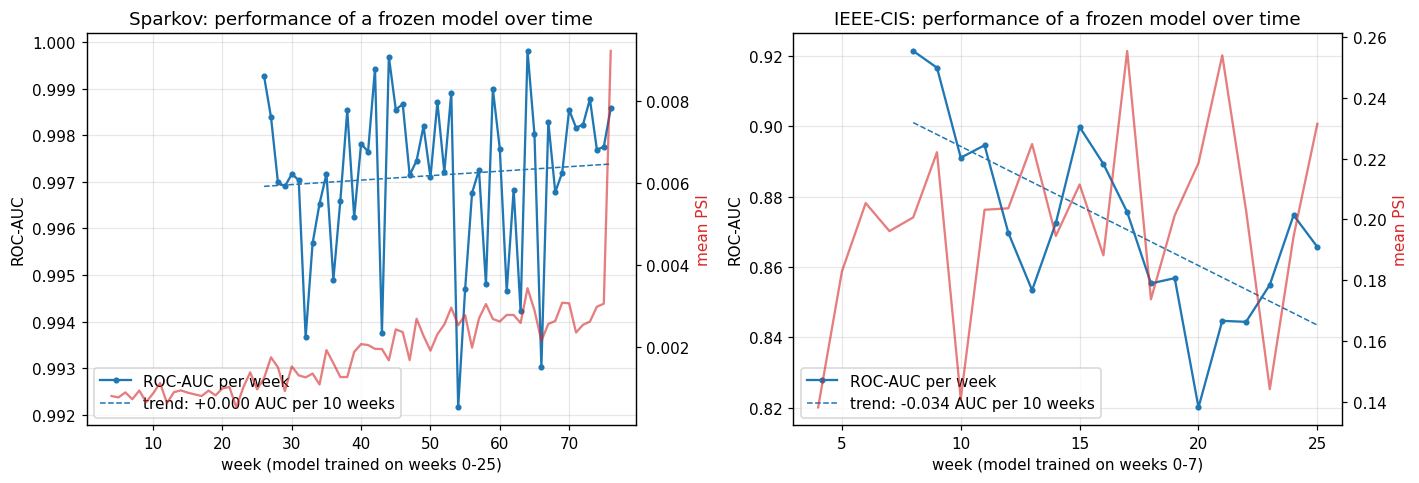

Sparkov: correlation between weekly mean PSI and weekly AUC = 0.16 over 51 weeks
IEEE-CIS: correlation between weekly mean PSI and weekly AUC = -0.12 over 18 weeks


In [6]:
def decay(df, features, train_weeks):
    train = df[df["week"] < train_weeks]
    w = np.where(train["label"] == 1, (train["label"] == 0).sum() / train["label"].sum(), 1.0)
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED)
    model.fit(train[features], train["label"], sample_weight=w)
    rows = []
    for week, g in df[df["week"] >= train_weeks].groupby("week"):
        if g["label"].nunique() == 2 and g["label"].sum() >= 5:
            rows.append({"week": week, "auc": roc_auc_score(g["label"], model.predict_proba(g[features])[:, 1]),
                         "frauds": int(g["label"].sum())})
    return pd.DataFrame(rows)


DECAY_SETUP = {"Sparkov": (sparkov, SPARKOV_FEATURES, 26), "IEEE-CIS": (ieee, IEEE_FEATURES, 8)}
decay_results = {name: decay(*setup) for name, setup in DECAY_SETUP.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, d) in zip(axes, decay_results.items()):
    ax.plot(d["week"], d["auc"], marker=".", color="tab:blue", label="ROC-AUC per week")
    z = np.polyfit(d["week"], d["auc"], 1)
    ax.plot(d["week"], np.polyval(z, d["week"]), color="tab:blue", ls="--", lw=1,
            label=f"trend: {z[0] * 10:+.3f} AUC per 10 weeks")
    ax.set_ylabel("ROC-AUC")
    ax.set_xlabel(f"week (model trained on weeks 0-{DECAY_SETUP[name][2] - 1})")
    psi_file = Path(f"../reports/04b_weekly_drift_{name.lower().replace('-', '_')}.csv")
    if psi_file.exists():
        psi = pd.read_csv(psi_file).groupby("week")["psi"].mean()
        ax2 = ax.twinx()
        ax2.plot(psi.index, psi.values, color="tab:red", alpha=0.6, label="mean PSI (notebook 04b)")
        ax2.set_ylabel("mean PSI", color="tab:red")
        ax2.grid(False)
    ax.set_title(f"{name}: performance of a frozen model over time")
    ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "04c_performance_decay_vs_psi.png", bbox_inches="tight")
plt.show()

for name, d in decay_results.items():
    psi_file = Path(f"../reports/04b_weekly_drift_{name.lower().replace('-', '_')}.csv")
    if psi_file.exists():
        psi = pd.read_csv(psi_file).groupby("week")["psi"].mean()
        joined = d.set_index("week").join(psi.rename("psi")).dropna()
        print(f"{name}: correlation between weekly mean PSI and weekly AUC = {joined['auc'].corr(joined['psi']):.2f} "
              f"over {len(joined)} weeks")

## 4. Fraud clusters on shared entities (Lecture 8: homophily and guilt by association)

Treat transactions that share an entity (the same card, merchant, address or email domain) as
linked. Lecture 8's homophily test compares the share of linked pairs with different labels
against the share expected if labels were random, `2p(1 - p)`. Here the pairs are
consecutive transactions on the same entity.

Then "guilt by association": is a transaction more likely to be fraud when the same entity
already had a confirmed fraud? This is computed twice:
- **no delay**: any earlier fraud counts;
- **7-day delay**: only frauds at least 7 days old count, because newer labels are not yet known.

The gap between the two shows how much of the signal disappears once label delay is respected.

In [7]:
def homophily(df, entity):
    d = df.dropna(subset=[entity]).sort_values("day")
    prev = d.groupby(entity)["label"].shift()
    pairs = pd.DataFrame({"a": prev, "b": d["label"]}).dropna()
    p = d["label"].mean()
    return {"pairs": len(pairs), "observed cross-label share": round((pairs["a"] != pairs["b"]).mean(), 4),
            "expected if random 2p(1-p)": round(2 * p * (1 - p), 4)}


def guilt_by_association(df, entity, delay_days):
    # a row is flagged when its entity already had a fraud known at the row's time:
    # the entity's first fraud day must be before the row's day (no delay),
    # or at least `delay_days` days before it (labels arrive late)
    d = df.dropna(subset=[entity])
    first_fraud_day = d.loc[d["label"] == 1].groupby(entity)["day"].min()
    known_from = d[entity].map(first_fraud_day) + max(delay_days, 0)
    flagged = (known_from < d["day"]).to_numpy() if delay_days > 0 else (d[entity].map(first_fraud_day) < d["day"]).to_numpy()
    return {"share of rows flagged (%)": round(100 * flagged.mean(), 2),
            "fraud rate if flagged (%)": round(100 * d.loc[flagged, "label"].mean(), 2) if flagged.any() else np.nan,
            "fraud rate otherwise (%)": round(100 * d.loc[~flagged, "label"].mean(), 2),
            "share of frauds flagged (%)": round(100 * d.loc[flagged, "label"].sum() / d["label"].sum(), 1)}


ENTITIES = {"Sparkov": (sparkov, ["cc_num", "merchant"]),
            "IEEE-CIS": (ieee, [c for c in ["card_id", "addr1", "P_emaildomain"] if c in ieee.columns])}
rows = []
for name, (df, ents) in ENTITIES.items():
    for e in ents:
        rows.append({"dataset": name, "entity": e, **homophily(df, e),
                     **{f"{k} | no delay": v for k, v in guilt_by_association(df, e, 0).items()},
                     **{f"{k} | 7-day delay": v for k, v in guilt_by_association(df, e, LABEL_DELAY_DAYS).items()}})
network = pd.DataFrame(rows).set_index(["dataset", "entity"])
display(network.T)

dataset                                         Sparkov                \
entity                                           cc_num      merchant   
pairs                                      1.295692e+06  1.295982e+06   
observed cross-label share                 1.100000e-03  1.140000e-02   
expected if random 2p(1-p)                 1.150000e-02  1.150000e-02   
share of rows flagged (%) | no delay       3.932000e+01  8.462000e+01   
fraud rate if flagged (%) | no delay       7.200000e-01  6.200000e-01   
fraud rate otherwise (%) | no delay        4.800000e-01  3.500000e-01   
share of frauds flagged (%) | no delay     4.920000e+01  9.070000e+01   
share of rows flagged (%) | 7-day delay    3.819000e+01  8.353000e+01   
fraud rate if flagged (%) | 7-day delay    0.000000e+00  6.200000e-01   
fraud rate otherwise (%) | 7-day delay     9.400000e-01  3.900000e-01   
share of frauds flagged (%) | 7-day delay  0.000000e+00  8.890000e+01   

dataset                                       IEEE-CIS               \
entity                                         card_id        addr1   
pairs                                      366699.0000  524502.0000   
observed cross-label share                      0.0177       0.0403   
expected if random 2p(1-p)                      0.0675       0.0480   
share of rows flagged (%) | no delay            1.9100      97.9800   
fraud rate if flagged (%) | no delay           68.5900       2.4700   
fraud rate otherwise (%) | no delay             2.2300       1.8900   
share of frauds flagged (%) | no delay         37.5000      98.5000   
share of rows flagged (%) | 7-day delay         1.1900      93.1400   
fraud rate if flagged (%) | 7-day delay        65.4600       2.4600   
fraud rate otherwise (%) | 7-day delay          2.7500       2.5200   
share of frauds flagged (%) | 7-day delay      22.2000      93.0000   

dataset                                                  
entity                                    P_emaildomain  
pairs                                       496025.0000  
observed cross-label share                       0.0593  
expected if random 2p(1-p)                       0.0695  
share of rows flagged (%) | no delay            97.8700  
fraud rate if flagged (%) | no delay             3.6500  
fraud rate otherwise (%) | no delay              1.4200  
share of frauds flagged (%) | no delay          99.2000  
share of rows flagged (%) | 7-day delay         93.4700  
fraud rate if flagged (%) | 7-day delay          3.6800  
fraud rate otherwise (%) | 7-day delay           2.5200  
share of frauds flagged (%) | 7-day delay       95.4000

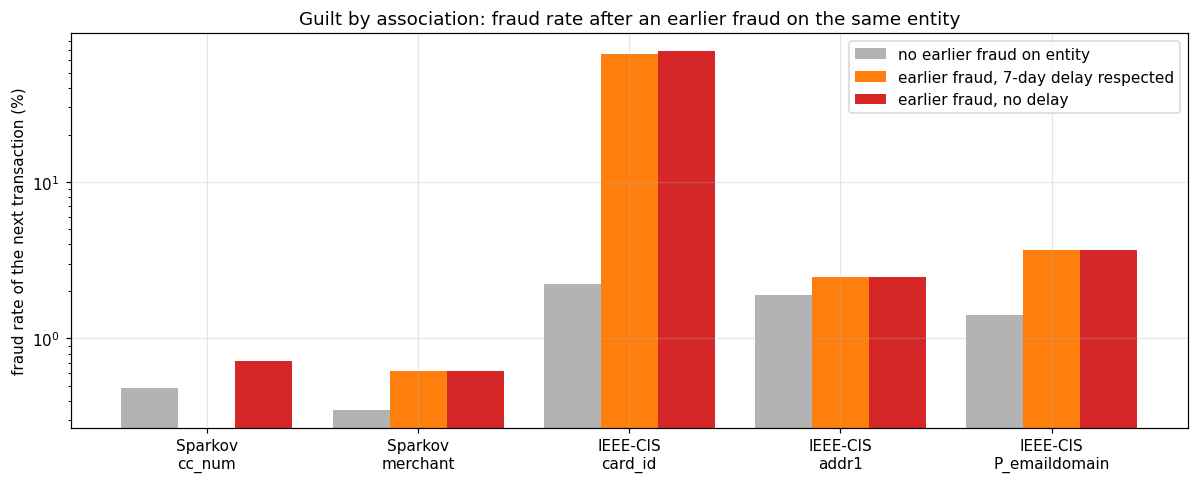

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [f"{d}\n{e}" for d, e in network.index]
x = np.arange(len(labels))
ax.bar(x - 0.27, network["fraud rate otherwise (%) | no delay"], 0.27, color="0.7", label="no earlier fraud on entity")
ax.bar(x, network["fraud rate if flagged (%) | 7-day delay"], 0.27, color="tab:orange", label="earlier fraud, 7-day delay respected")
ax.bar(x + 0.27, network["fraud rate if flagged (%) | no delay"], 0.27, color="tab:red", label="earlier fraud, no delay")
ax.set_xticks(x, labels)
ax.set_ylabel("fraud rate of the next transaction (%)")
ax.set_yscale("log")
ax.set_title("Guilt by association: fraud rate after an earlier fraud on the same entity")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04c_guilt_by_association.png", bbox_inches="tight")
plt.show()

## Summary

- **Adversarial validation.**
  - IEEE-CIS: early and late periods can be told apart (AUC 0.91). No single feature dominates; the strongest are C9 and the D columns (single-feature AUC 0.55 to 0.59), so the drift is spread over many features.
  - Sparkov: the classifier reaches 0.99 although every single feature is near 0.5. Section 1b shows why: **age** (transaction date minus date of birth) combined with a customer-identifying attribute such as `city_pop` acts as a clock (AUC 0.96 with these two alone, 0.50 without age). The same customer is a little older in every later transaction, so a tree model can learn when a transaction happened.
- **Time-counting features.**
  - The raw IEEE-CIS D columns are only weakly correlated with time (Spearman 0.10 or less for D1 to D15), so they mostly do not simply count calendar time.
  - The re-anchored `day - D` is strongly tied to time (0.3 to 1.0): it is a fixed date per card, useful as a card key (as in notebook 03) but not as a model feature.
- **Performance decay.**
  - A model trained once on IEEE-CIS weeks 0 to 7 falls from 0.92 to about 0.84 ROC-AUC over the next 18 weeks (trend -0.034 per 10 weeks).
  - The Sparkov model stays at 0.993 to 0.999 with no trend.
  - Week-to-week PSI barely tracks week-to-week AUC (correlation 0.16 and -0.12): the loss builds up with the time gap rather than following each week's drift score.
  - This is a clear, testable prediction for M2: sliding-window retraining should help on IEEE-CIS and change little on Sparkov.
- **Homophily and guilt by association.**
  - Both datasets are strongly homophilic on cards: consecutive transactions on the same card have different labels in 0.11% (Sparkov) and 1.8% (IEEE-CIS) of pairs, against 1.2% and 6.8% expected at random.
  - Sparkov: once the 7-day label delay is respected, an earlier confirmed fraud on the card never precedes a later fraud (0% of frauds flagged), because each card's frauds come in one burst shorter than a week. Card-history gains on Sparkov must come from behaviour (velocity, amounts), not from known labels.
  - IEEE-CIS: after an earlier fraud on the same reconstructed card, the next transaction is fraud 68.6% of the time (65.5% with the delay, against 2.2% to 2.8% otherwise), and 22% of all frauds are still flagged under the delay. This is Vesta's label propagation, and it is exactly the TA's concern: a card-history label feature would be very strong but partly trivial.
  - Coarse entities (merchant, `addr1`, email domain) carry only a weak signal (1.3 to 2.6 times the base rate).
- **Recommendations.**
  - Feature engineering: replace `age` with age at a fixed reference date or in coarse bands; keep raw D columns and use `day - D1` only as a card key.
  - Experiments: report results separately with and without label-based card history on IEEE-CIS; in M2, expect a gain on IEEE-CIS but not on Sparkov; in M3, respect the 7-day delay, since Sparkov's label signal disappears under it.